# Exploratory Data Analysis (EDA) – Retail Sales & Profitability Intelligence

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (
            path / "data" / "processed" /
            "Superstore_cleaned.csv"
        ).is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the processed dataset."
    )

data_path = (
    project_root
    / "data"
    / "processed"
    / "Superstore_cleaned.csv"
)

df = pd.read_csv(
    data_path,
    encoding="utf-8-sig",
    dtype={"Postal Code": "string"}
)

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Dataset loaded successfully!")
print("File:", data_path.name)
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: Superstore_cleaned.csv
Dataset shape: (9993, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Univariate Analysis

### 1. Numerical Features

In [2]:
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]

numeric_summary = df[numeric_cols].describe().T

numeric_summary["skewness"] = df[numeric_cols].skew()
numeric_summary["missing_values"] = df[numeric_cols].isna().sum()

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness,missing_values
Sales,9993.0,229.85,623.28,0.44,17.28,54.48,209.94,22638.48,12.97,0
Quantity,9993.0,3.79,2.23,1.00,2.00,3.00,5.00,14.00,1.28,0
Discount,9993.0,0.16,0.21,0.00,0.00,0.20,0.20,0.80,1.68,0
Profit,9993.0,28.66,234.27,-6599.98,1.73,8.67,29.36,8399.98,7.56,0


### 2. Distribution Analysis: Numerical Features

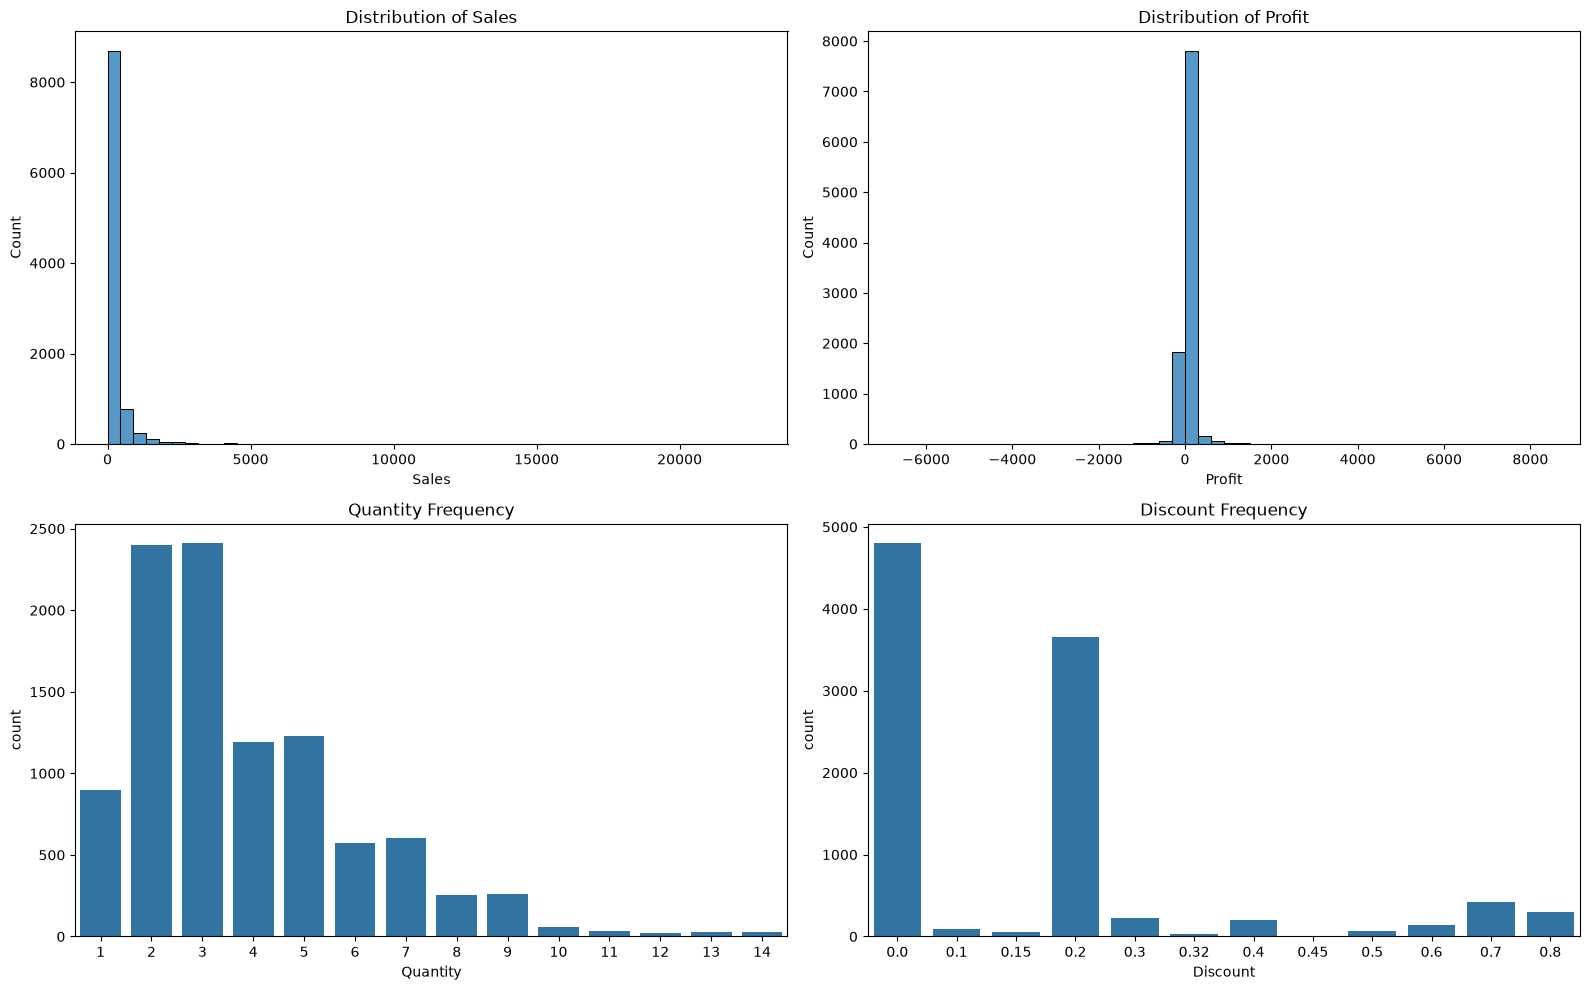

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.histplot(data=df, x="Sales", bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Sales")

sns.histplot(data=df, x="Profit", bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Profit")

sns.countplot(data=df, x="Quantity", order=sorted(df["Quantity"].dropna().unique()), ax=axes[1, 0])
axes[1, 0].set_title("Quantity Frequency")

sns.countplot(data=df, x="Discount", order=sorted(df["Discount"].dropna().unique()), ax=axes[1, 1])
axes[1, 1].set_title("Discount Frequency")

plt.tight_layout()
plt.show()

### 3. Outlier Detection Using Boxplots


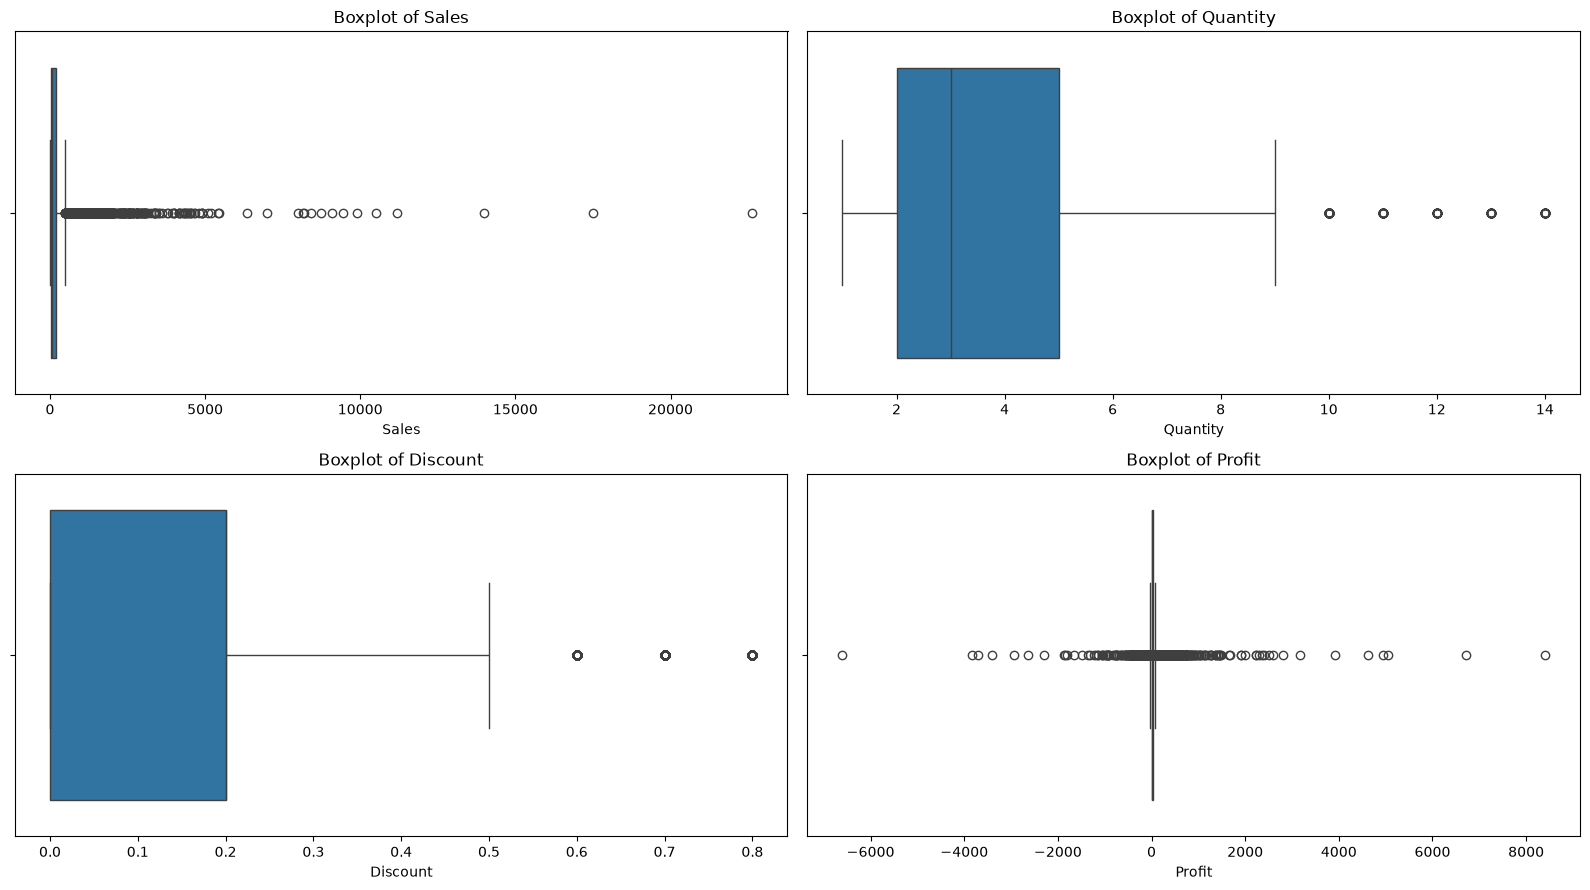

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for col, ax in zip(numeric_cols, axes.flatten()):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

### 4. IQR-Based Outlier Detection

In [5]:
outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (len(outliers) / len(df)) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Variable,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,Sales,17.28,209.94,192.66,-271.71,498.93,1167,11.68
1,Quantity,2.00,5.00,3.00,-2.50,9.50,170,1.70
2,Discount,0.00,0.20,0.20,-0.30,0.50,856,8.57
3,Profit,1.73,29.36,27.63,-39.72,70.81,1881,18.82


In [6]:
outlier_columns = [
    "Row ID",
    "Order ID",
    "Product Name",
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nTop 5 extreme records for {col}:")

    if col == "Profit":
        display(outliers.reindex(
            outliers["Profit"].abs().sort_values(ascending=False).head(5).index
        )[outlier_columns])
    else:
        display(outliers.nlargest(5, col)[outlier_columns])


Top 5 extreme records for Sales:


,Row ID,Order ID,Product Name,Sales,Quantity,Discount,Profit
2697,2698,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784
6825,6827,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
8152,8154,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
2623,2624,CA-2017-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,4,0.2,3919.9888
4189,4191,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856



Top 5 extreme records for Quantity:


,Row ID,Order ID,Product Name,Sales,Quantity,Discount,Profit
113,114,CA-2014-115259,"OIC Colored Binder Clips, Assorted Sizes",40.096,14,0.2,14.5348
139,140,CA-2016-145583,Longer-Life Soft White Bulbs,43.120,14,0.0,20.6976
575,576,CA-2015-149713,Personal Creations Ink Jet Cards and Labels,160.720,14,0.0,78.7528
660,661,CA-2015-146563,Space Solutions Commercial Steel Shelving,724.080,14,0.2,-135.7650
1045,1046,CA-2017-152702,"Global Stack Chair without Arms, Black",254.604,14,0.3,-18.1860



Top 5 extreme records for Discount:


,Row ID,Order ID,Product Name,Sales,Quantity,Discount,Profit
14,15,US-2015-118983,Holmes Replacement Filter for HEPA Air Cleaner...,68.810,5,0.8,-123.8580
15,16,US-2015-118983,Storex DuraTech Recycled Plastic Frosted Binders,2.544,3,0.8,-3.8160
75,76,US-2017-118038,Economy Binders,1.248,3,0.8,-1.9344
101,102,CA-2016-158568,Avery Hidden Tab Dividers for Binding Systems,1.788,3,0.8,-3.0396
169,170,CA-2014-139892,Kensington 7 Outlet MasterPiece Power Center,177.980,5,0.8,-453.8490



Top 5 extreme records for Profit:


,Row ID,Order ID,Product Name,Sales,Quantity,Discount,Profit
6825,6827,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
8152,8154,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
7771,7773,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
4189,4191,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856
9038,9040,CA-2016-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,0.0,4946.3700


### Outlier Analysis Findings

The IQR method identified potential outliers in all four numerical variables:

- Sales: 1,167 (11.68%)
- Quantity: 170 (1.70%)
- Discount: 856 (8.57%)
- Profit: 1,881 (18.82%)

Inspection revealed legitimate high-value transactions, larger order quantities,
high-discount transactions, and unusually high profits or losses.

No clear data-entry errors were identified from the inspected records.
Therefore, no observations were removed based solely on the IQR method.

All 9,993 records were retained for further analysis.

### 5. Categorical Analysis: Frequency Distribution

In [7]:
categorical_cols = [
    "Segment",
    "Region",
    "Category",
    "Sub-Category",
    "Ship Mode"
]

for col in categorical_cols:
    print(f"\nFrequency Distribution of {col}")

    summary = (
        df[col]
        .value_counts(dropna=False)
        .reset_index()
    )

    summary.columns = [col, "Count"]

    summary["Percentage"] = (
        summary["Count"] / len(df) * 100
    ).round(2)

    display(summary)


Frequency Distribution of Segment


,Segment,Count,Percentage
0,Consumer,5191,51.95
1,Corporate,3020,30.22
2,Home Office,1782,17.83



Frequency Distribution of Region


,Region,Count,Percentage
0,West,3203,32.05
1,East,2847,28.49
2,Central,2323,23.25
3,South,1620,16.21



Frequency Distribution of Category


,Category,Count,Percentage
0,Office Supplies,6026,60.30
1,Furniture,2120,21.21
2,Technology,1847,18.48



Frequency Distribution of Sub-Category


,Sub-Category,Count,Percentage
0,Binders,1523,15.24
1,Paper,1370,13.71
2,Furnishings,957,9.58
3,Phones,889,8.90
4,Storage,846,8.47
5,Art,796,7.97
6,Accessories,775,7.76
7,Chairs,616,6.16
8,Appliances,466,4.66
9,Labels,364,3.64



Frequency Distribution of Ship Mode


,Ship Mode,Count,Percentage
0,Standard Class,5967,59.71
1,Second Class,1945,19.46
2,First Class,1538,15.39
3,Same Day,543,5.43


### 6. Visualization of Categorical Variables

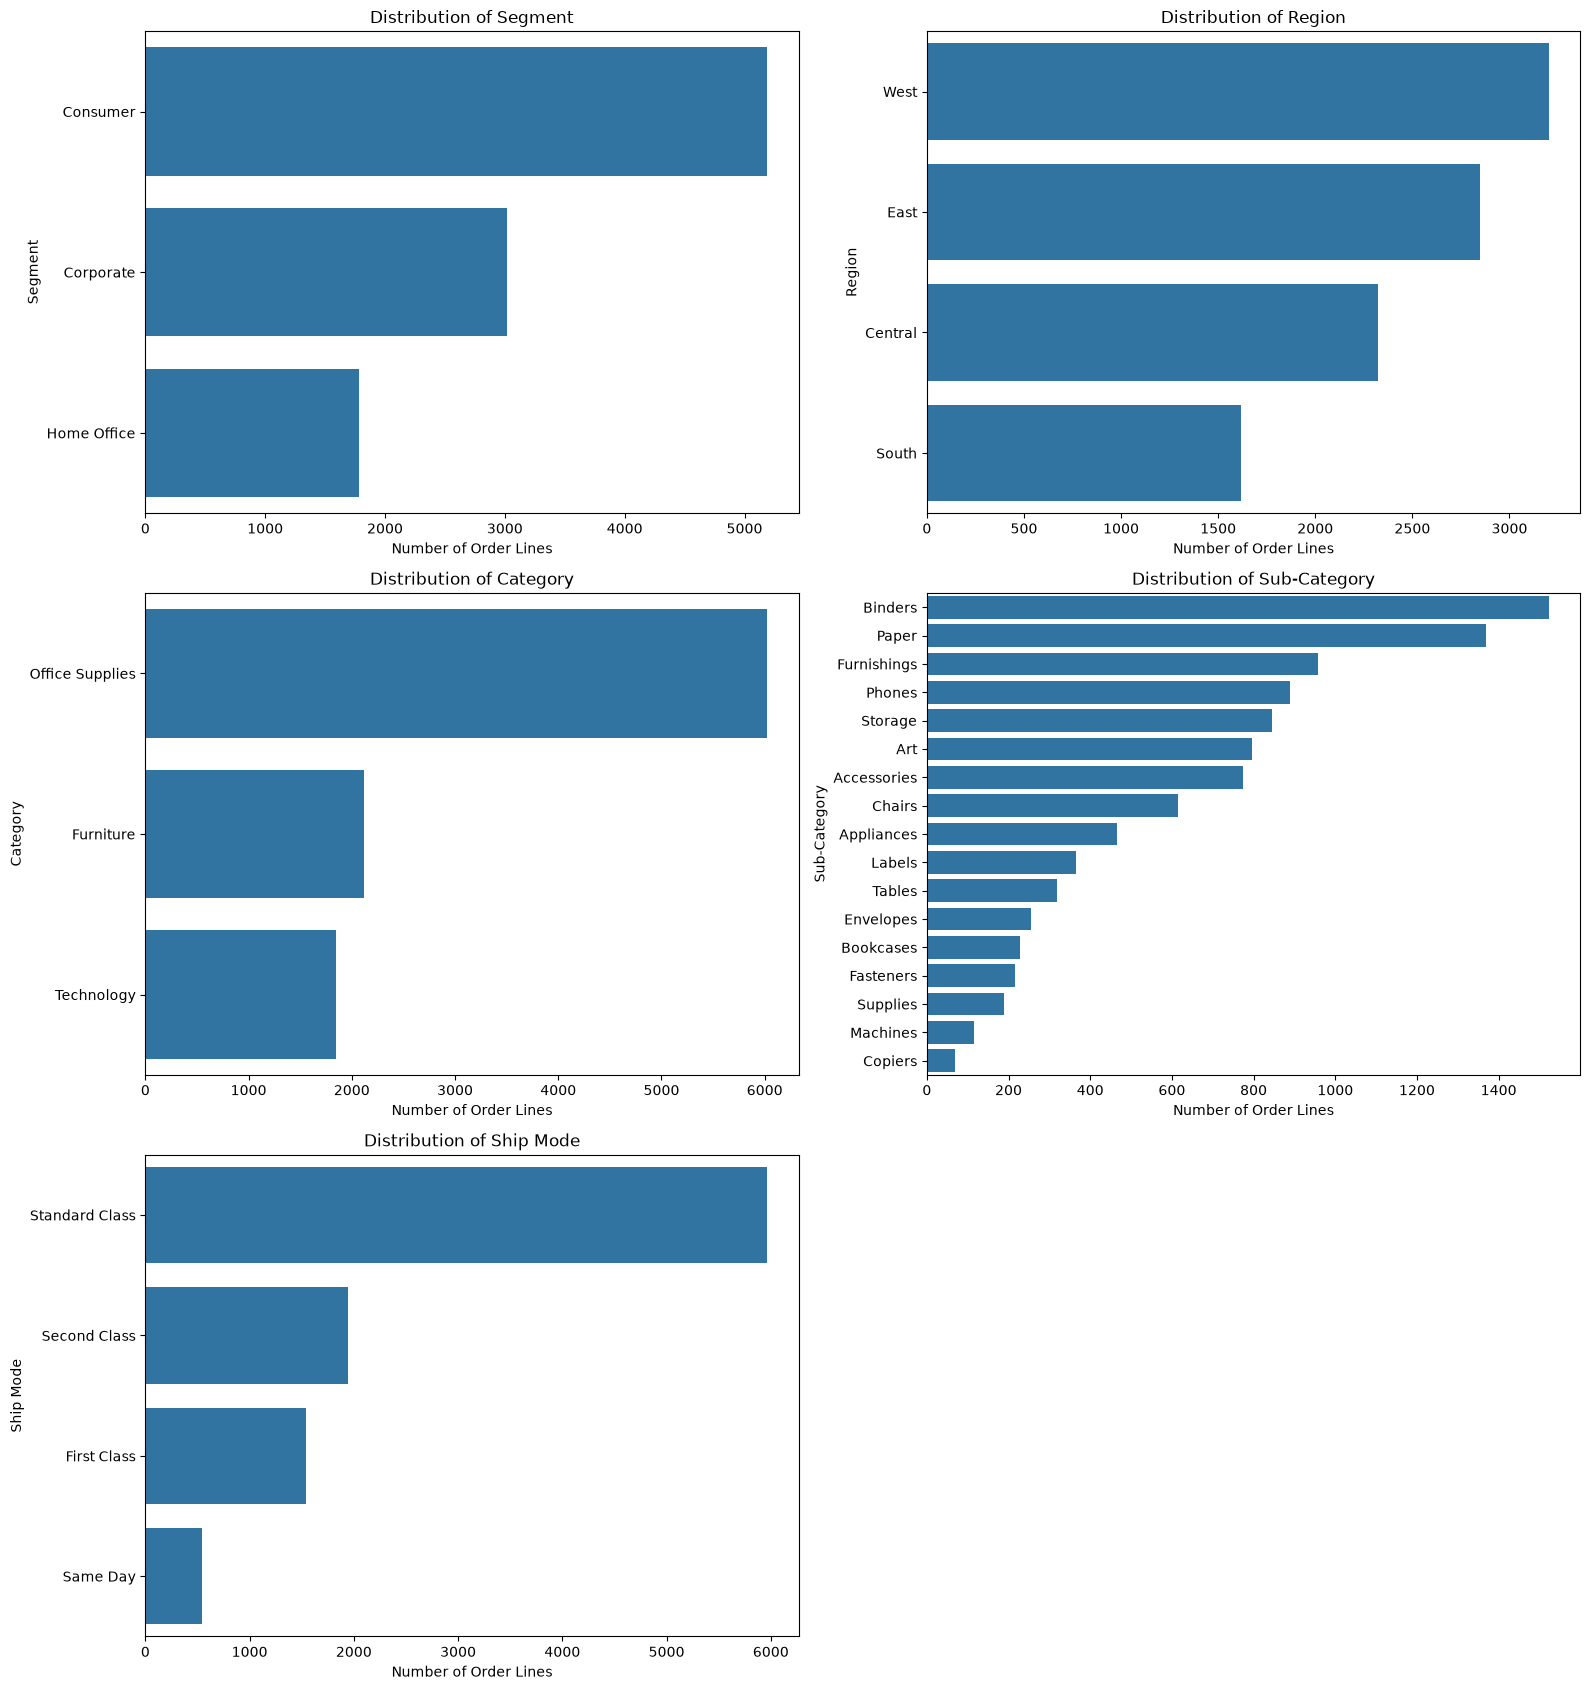

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

for col, ax in zip(categorical_cols, axes.flatten()):
    counts = df[col].value_counts()

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Number of Order Lines")
    ax.set_ylabel(col)

for ax in axes.flatten()[len(categorical_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

## 2. Bivariate analysis: Category vs. business performance

### 7. Category-wise Business Performance

In [9]:
category_analysis = (
    df.groupby("Category")
    .agg(
        order_lines=("Row ID", "count"),
        total_quantity=("Quantity", "sum"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

category_analysis["profit_margin"] = (
    category_analysis["total_profit"] /
    category_analysis["total_sales"] * 100
)

category_analysis = category_analysis.sort_values(
    by="total_profit",
    ascending=False
)

display(category_analysis.round(2))

,Category,order_lines,total_quantity,total_sales,total_profit,profit_margin
2,Technology,1847,6939,836154.03,145454.95,17.40
1,Office Supplies,6026,22906,719047.03,122490.80,17.04
0,Furniture,2120,8026,741718.42,18463.33,2.49


### 8. Category-wise Sales, Profit and Profit Margin

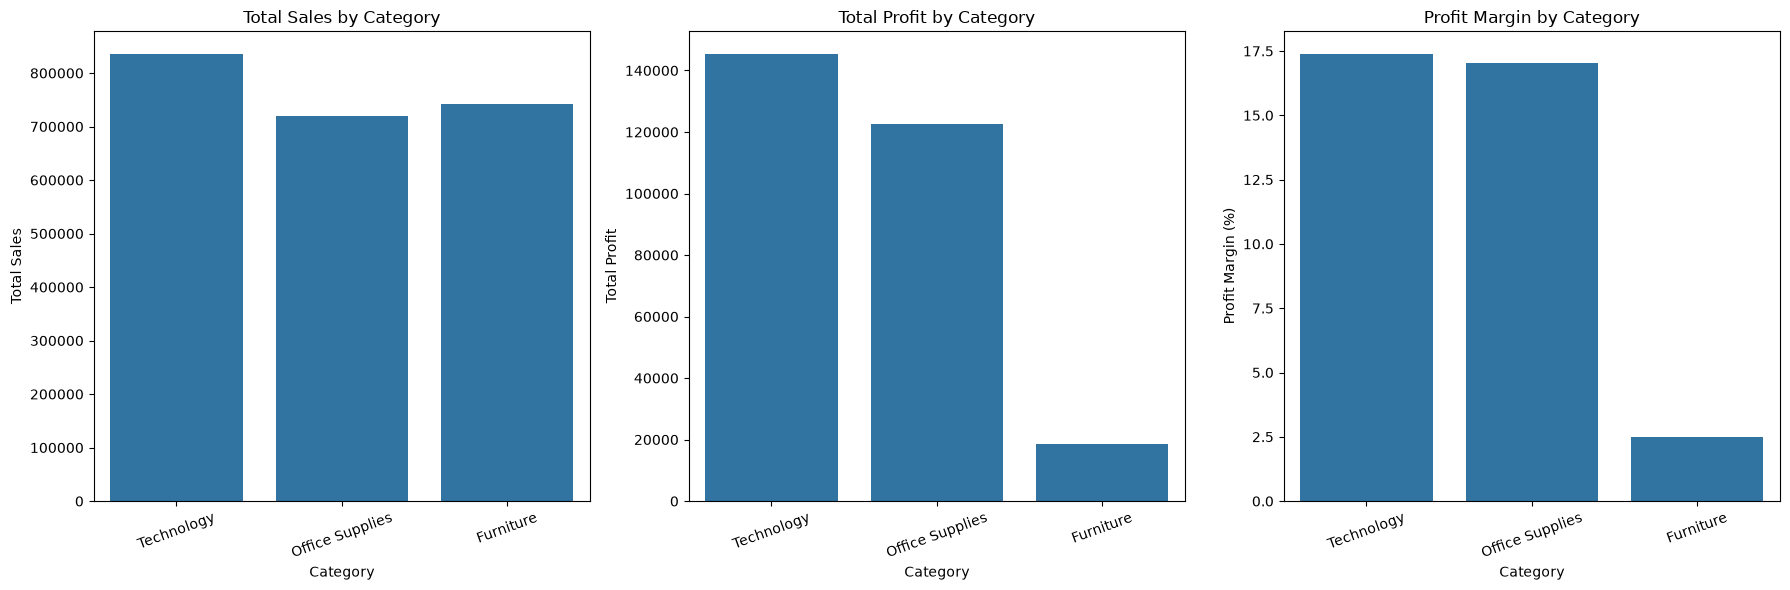

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Category")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=category_analysis,
    x="Category",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Category")
axes[1].set_ylabel("Total Profit")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=category_analysis,
    x="Category",
    y="profit_margin",
    ax=axes[2]
)
axes[2].set_title("Profit Margin by Category")
axes[2].set_ylabel("Profit Margin (%)")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 9. Subcategory-wise Sales and Profitability Analysis

In [12]:
subcategory_analysis = (
    df.groupby("Sub-Category")
    .agg(
        order_lines=("Row ID", "count"),
        total_quantity=("Quantity", "sum"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

subcategory_analysis["profit_margin"] = (
    subcategory_analysis["total_profit"]
    / subcategory_analysis["total_sales"] * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    by="total_profit",
    ascending=True
)

display(subcategory_analysis.round(2))

,Sub-Category,order_lines,total_quantity,total_sales,total_profit,profit_margin
16,Tables,319,1241,206965.53,-17725.48,-8.56
4,Bookcases,228,868,114880.00,-3472.56,-3.02
15,Supplies,190,647,46673.54,-1189.10,-2.55
8,Fasteners,217,914,3024.28,949.52,31.40
11,Machines,115,440,189238.63,3384.76,1.79
10,Labels,364,1400,12486.31,5546.25,44.42
2,Art,796,3000,27118.79,6527.79,24.07
7,Envelopes,254,906,16476.40,6964.18,42.27
9,Furnishings,957,3563,91705.16,13059.14,14.24
1,Appliances,466,1729,107532.16,18138.01,16.87


### 10. Subcategory-wise Profit and Profit Margin Visualization

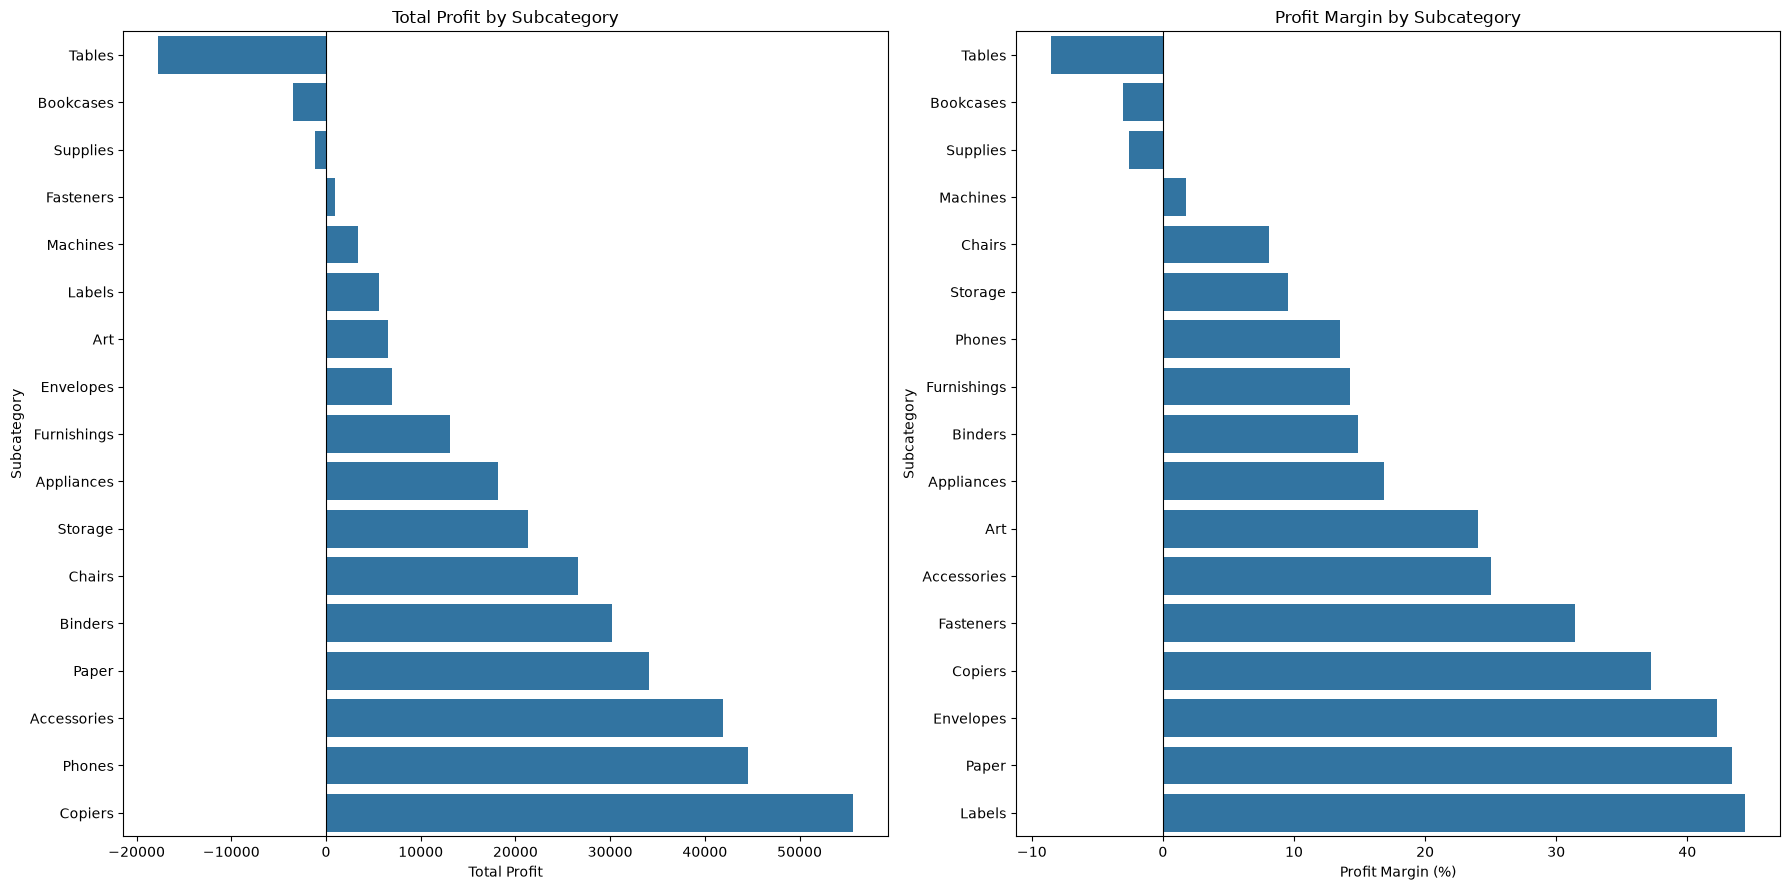

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

profit_order = subcategory_analysis.sort_values(
    by="total_profit"
)["Sub-Category"]

margin_order = subcategory_analysis.sort_values(
    by="profit_margin"
)["Sub-Category"]

sns.barplot(
    data=subcategory_analysis,
    x="total_profit",
    y="Sub-Category",
    order=profit_order,
    ax=axes[0]
)

axes[0].set_title("Total Profit by Subcategory")
axes[0].set_xlabel("Total Profit")
axes[0].set_ylabel("Subcategory")
axes[0].axvline(0, color="black", linewidth=0.8)

sns.barplot(
    data=subcategory_analysis,
    x="profit_margin",
    y="Sub-Category",
    order=margin_order,
    ax=axes[1]
)

axes[1].set_title("Profit Margin by Subcategory")
axes[1].set_xlabel("Profit Margin (%)")
axes[1].set_ylabel("Subcategory")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

### Subcategory Profitability Findings

- Tables, Bookcases and Supplies are the three loss-making subcategories.
- Tables records the largest loss of $17,725.48.
- Copiers generates the highest total profit of $55,617.82.
- Paper has the highest profit margin at 43.39%.
- Phones generates the highest subcategory sales at $330,007.05.
- Machines generates substantial sales but has a low profit margin of 1.79%.

These findings indicate that sales volume, total profit and profit margin
must be evaluated together to understand product performance.

### 11. Customer Segment-wise Business Performance

In [14]:
segment_analysis = (
    df.groupby("Segment")
    .agg(
        order_lines=("Row ID", "count"),
        unique_orders=("Order ID", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        total_quantity=("Quantity", "sum")
    )
    .reset_index()
)

segment_analysis["profit_margin"] = (
    segment_analysis["total_profit"]
    / segment_analysis["total_sales"] * 100
)

segment_analysis["sales_per_customer"] = (
    segment_analysis["total_sales"]
    / segment_analysis["unique_customers"]
)

segment_analysis = segment_analysis.sort_values(
    by="total_profit",
    ascending=False
)

display(segment_analysis.round(2))

,Segment,order_lines,unique_orders,unique_customers,total_sales,total_profit,total_quantity,profit_margin,sales_per_customer
0,Consumer,5191,2586,409,1161401.34,134119.21,19521,11.55,2839.61
1,Corporate,3020,1514,236,706146.37,91979.13,11608,13.03,2992.15
2,Home Office,1782,909,148,429371.78,60310.74,6742,14.05,2901.16


### 12. Customer Segment-wise Sales and Profitability Visualization

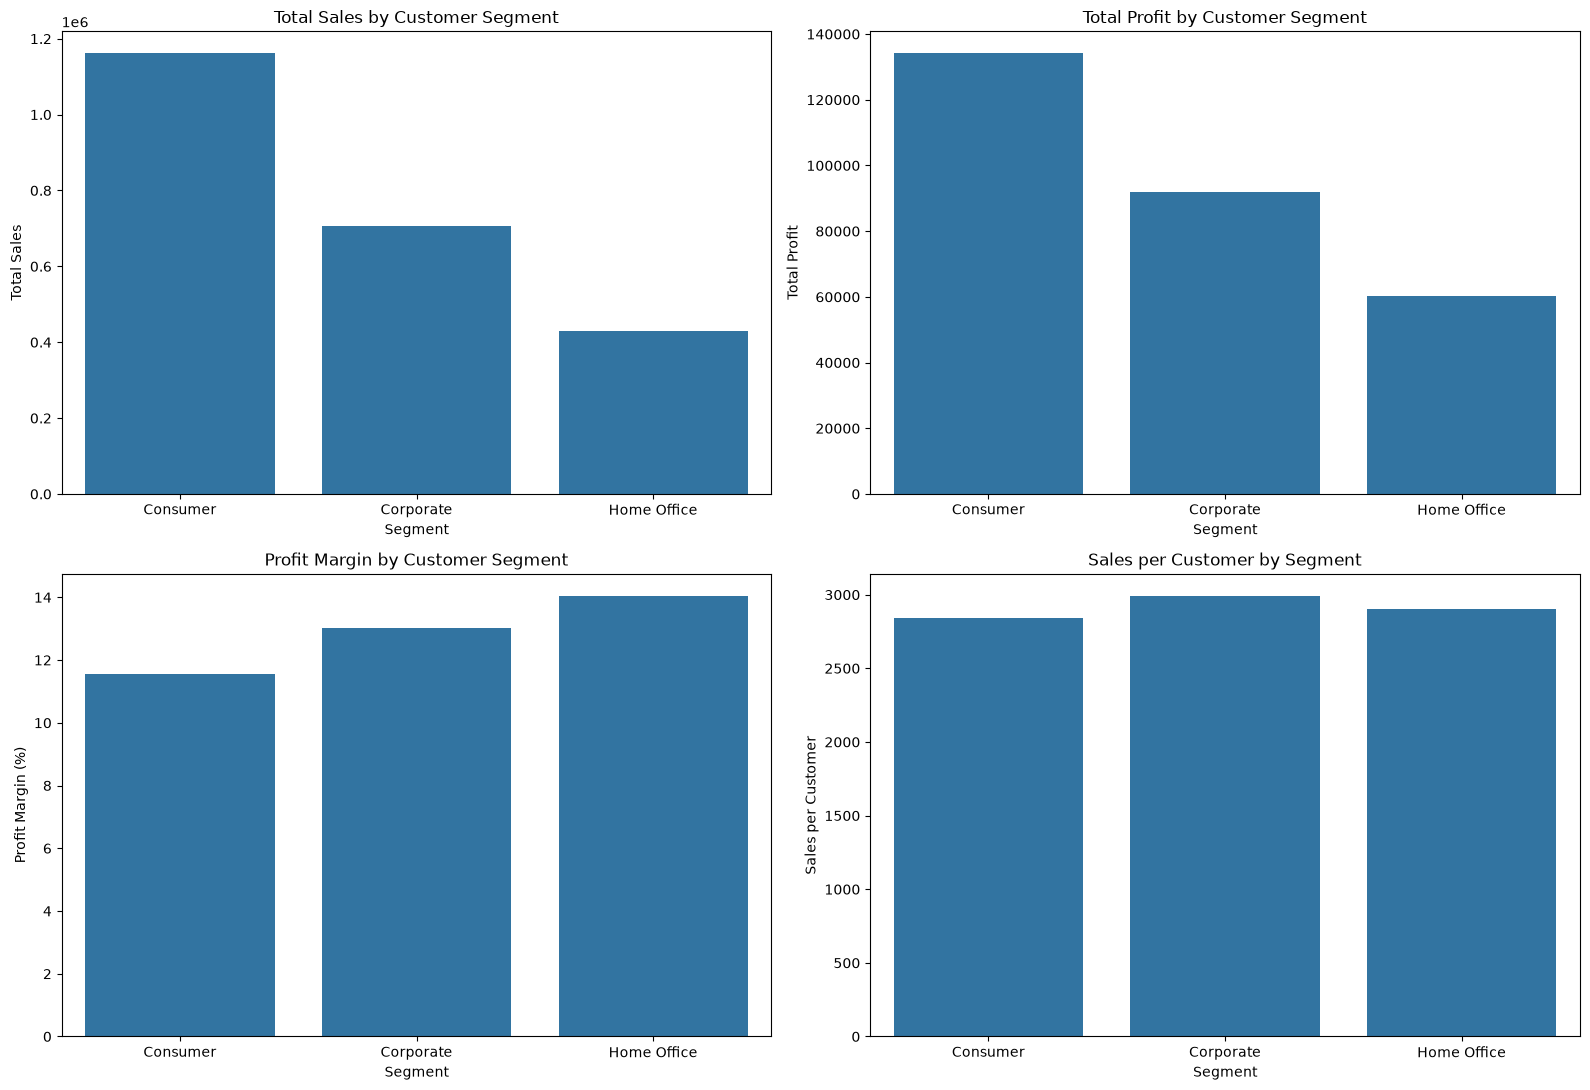

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="total_sales",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Sales by Customer Segment")
axes[0, 0].set_ylabel("Total Sales")

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="total_profit",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Total Profit by Customer Segment")
axes[0, 1].set_ylabel("Total Profit")

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="profit_margin",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Profit Margin by Customer Segment")
axes[1, 0].set_ylabel("Profit Margin (%)")

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="sales_per_customer",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Sales per Customer by Segment")
axes[1, 1].set_ylabel("Sales per Customer")

plt.tight_layout()
plt.show()

### Customer Segment Analysis Findings

- Consumer contributes the highest sales of $1,161,401.34 and profit of $134,119.21.
- Home Office records the highest profit margin at 14.05%.
- Corporate generates the highest sales per customer at $2,992.15.
- Consumer has the highest customer count, but its profit margin is the lowest among the three segments.

The results show that customer volume and profitability differ across segments.
Business decisions should consider total sales, total profit, profit margin
and sales per customer together.

### 13. Regional Sales and Profitability Analysis

In [16]:
region_analysis = (
    df.groupby("Region")
    .agg(
        order_lines=("Row ID", "count"),
        unique_orders=("Order ID", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

region_analysis["profit_margin"] = (
    region_analysis["total_profit"]
    / region_analysis["total_sales"] * 100
)

region_analysis["sales_per_customer"] = (
    region_analysis["total_sales"]
    / region_analysis["unique_customers"]
)

region_analysis = region_analysis.sort_values(
    by="total_profit",
    ascending=False
)

display(region_analysis.round(2))

,Region,order_lines,unique_orders,unique_customers,total_quantity,total_sales,total_profit,profit_margin,sales_per_customer
3,West,3203,1611,686,12266,725457.82,108418.45,14.94,1057.52
1,East,2847,1401,674,10616,678499.87,91534.84,13.49,1006.68
2,South,1620,822,512,6209,391721.90,46749.43,11.93,765.08
0,Central,2323,1175,629,8780,501239.89,39706.36,7.92,796.88


### 14. Regional Sales and Profitability Visualization

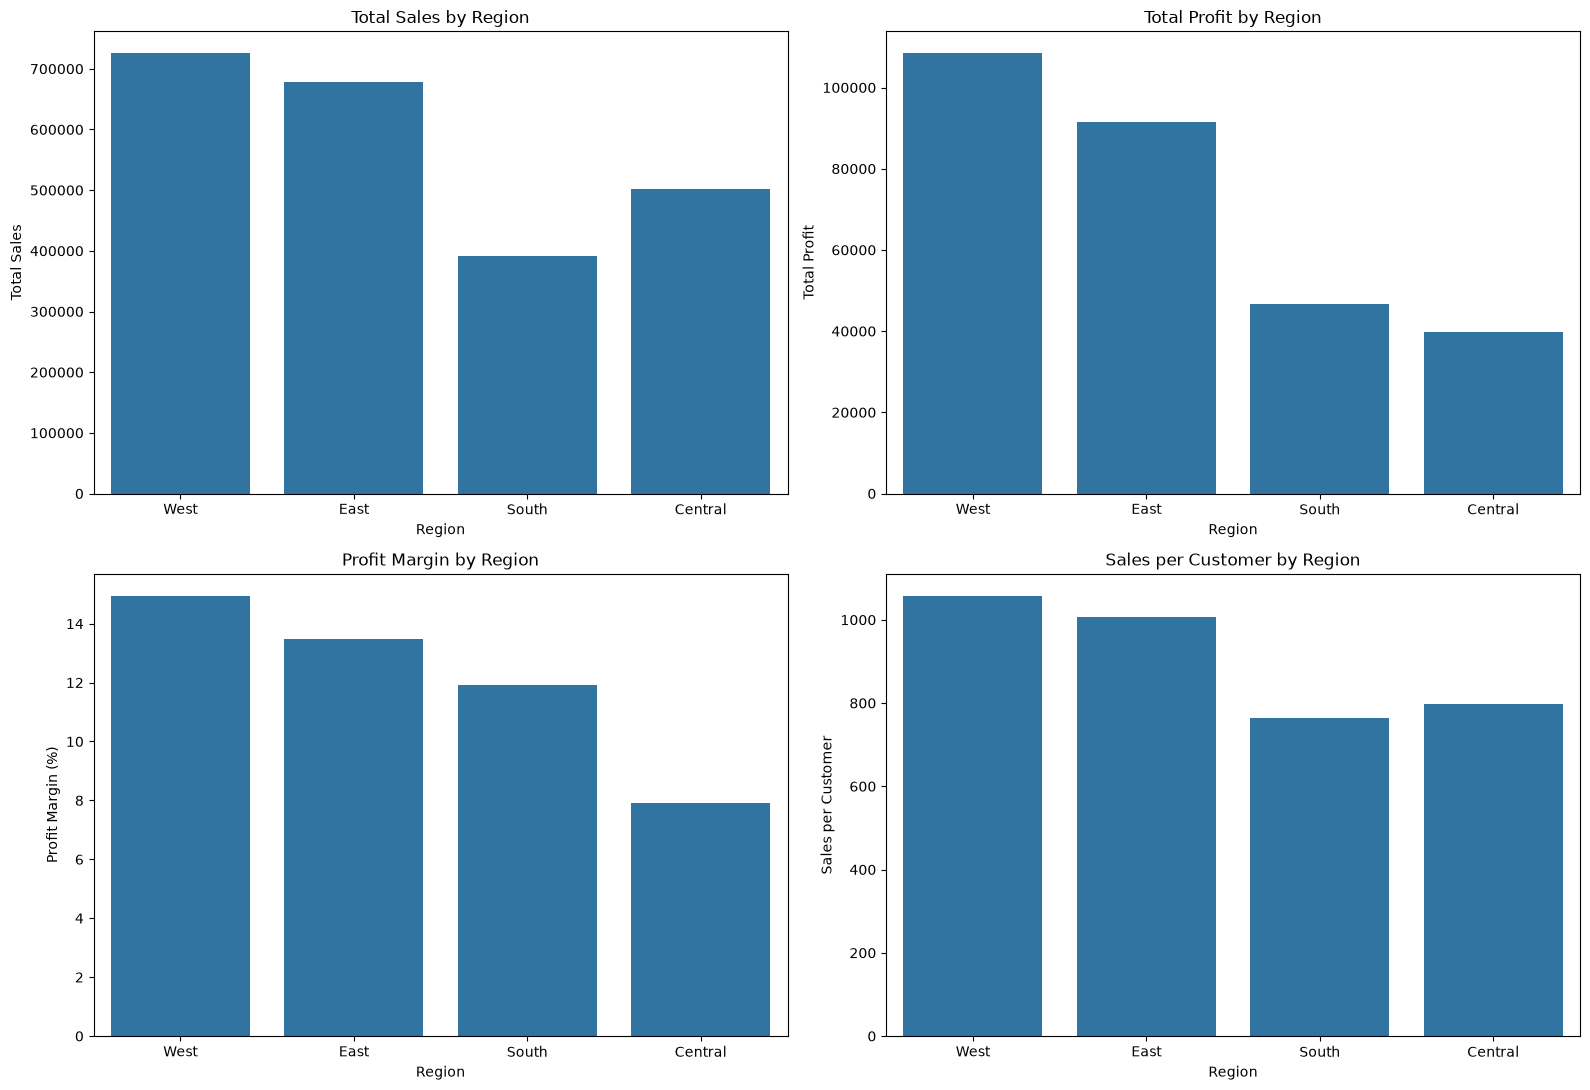

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="total_sales",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Sales by Region")
axes[0, 0].set_ylabel("Total Sales")

sns.barplot(
    data=region_analysis,
    x="Region",
    y="total_profit",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Total Profit by Region")
axes[0, 1].set_ylabel("Total Profit")

sns.barplot(
    data=region_analysis,
    x="Region",
    y="profit_margin",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Profit Margin by Region")
axes[1, 0].set_ylabel("Profit Margin (%)")

sns.barplot(
    data=region_analysis,
    x="Region",
    y="sales_per_customer",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Sales per Customer by Region")
axes[1, 1].set_ylabel("Sales per Customer")

plt.tight_layout()
plt.show()

### Regional Performance Findings

- West generates the highest sales of $725,457.82 and profit of $108,418.45.
- West also records the highest profit margin at 14.94%.
- East is the second-largest contributor to sales and profit.
- Central has the lowest profit margin at 7.92%, despite generating $501,239.89 in sales.
- South has the lowest total sales but maintains a profit margin of 11.93%.
- West records the highest regional sales per customer at $1,057.52.

The results indicate considerable differences in regional profitability.
Central deserves further investigation to identify potential product,
discount and state-level profitability issues.

### 15. State-wise Sales and Profitability Analysis

In [18]:
state_analysis = (
    df.groupby("State")
    .agg(
        order_lines=("Row ID", "count"),
        unique_orders=("Order ID", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

state_analysis["profit_margin"] = (
    state_analysis["total_profit"]
    / state_analysis["total_sales"] * 100
)

state_analysis = state_analysis.sort_values(
    by="total_profit",
    ascending=True
)

print("Total geographical entries:", len(state_analysis))

print(
    "Loss-making states:",
    (state_analysis["total_profit"] < 0).sum()
)

print("\n10 Lowest-performing states:")
display(state_analysis.head(10).round(2))

print("\n10 Highest-profit states:")
display(
    state_analysis.tail(10)
    .sort_values(by="total_profit", ascending=False)
    .round(2)
)

Total geographical entries: 49
Loss-making states: 10

10 Lowest-performing states:


,State,order_lines,unique_orders,unique_customers,total_quantity,total_sales,total_profit,profit_margin
41,Texas,985,487,370,3724,170188.05,-25729.36,-15.12
33,Ohio,468,236,202,1757,77976.76,-16959.32,-21.75
36,Pennsylvania,587,288,257,2153,116511.91,-15559.96,-13.35
11,Illinois,492,276,237,1845,80166.10,-12607.89,-15.73
31,North Carolina,249,136,122,983,55603.16,-7490.91,-13.47
4,Colorado,182,79,75,693,32108.12,-6527.86,-20.33
40,Tennessee,183,91,84,681,30661.87,-5341.69,-17.42
1,Arizona,224,108,100,862,35282.00,-3427.92,-9.72
8,Florida,383,200,181,1379,89473.71,-3399.30,-3.80
35,Oregon,124,56,51,499,17431.15,-1190.47,-6.83



10 Highest-profit states:


,State,order_lines,unique_orders,unique_customers,total_quantity,total_sales,total_profit,profit_margin
3,California,2001,1021,577,7667,457687.63,76381.39,16.69
30,New York,1128,562,415,4224,310876.27,74038.55,23.82
45,Washington,506,256,224,1883,138641.27,33402.65,24.09
20,Michigan,255,117,106,946,76269.61,24463.19,32.07
44,Virginia,224,115,107,893,70636.72,18597.95,26.33
12,Indiana,149,73,70,578,53555.36,18382.94,34.33
9,Georgia,184,91,83,705,49095.84,16250.04,33.10
15,Kentucky,139,61,58,523,36591.75,11199.70,30.61
21,Minnesota,89,44,42,331,29863.15,10823.19,36.24
6,Delaware,96,44,43,367,27451.07,9977.37,36.35


### 16. Top and Bottom Performing States

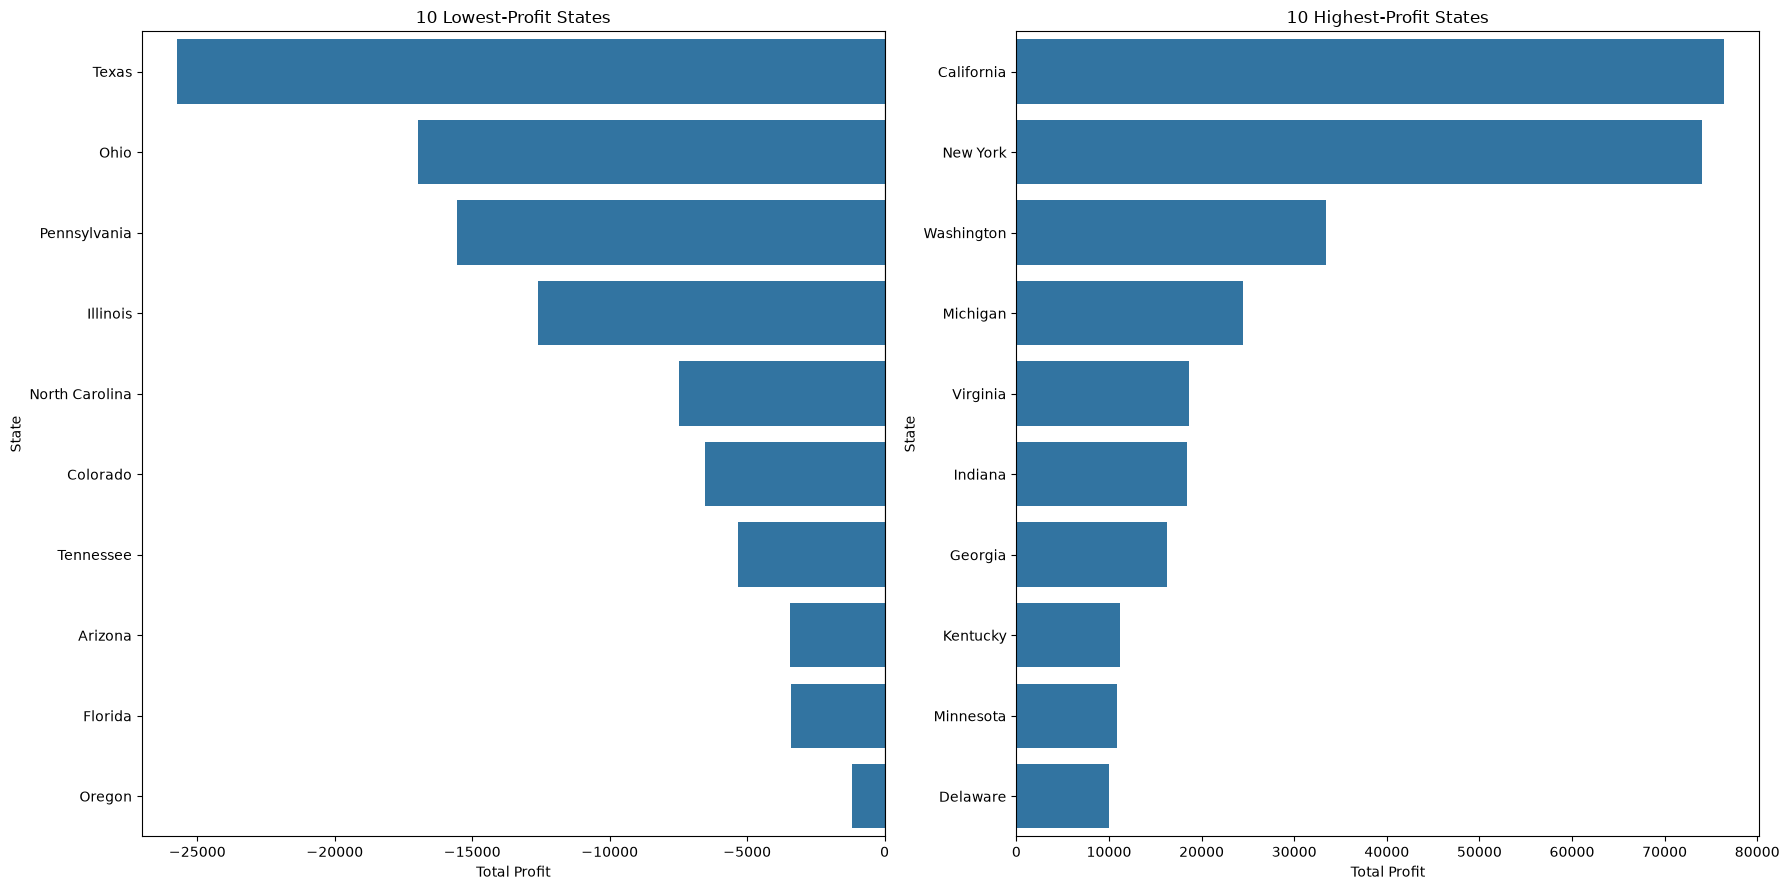

In [19]:
worst_states = state_analysis.nsmallest(10, "total_profit")

top_states = state_analysis.nlargest(10, "total_profit")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

sns.barplot(
    data=worst_states,
    x="total_profit",
    y="State",
    order=worst_states["State"],
    ax=axes[0]
)

axes[0].set_title("10 Lowest-Profit States")
axes[0].set_xlabel("Total Profit")
axes[0].set_ylabel("State")
axes[0].axvline(0, color="black", linewidth=0.8)

sns.barplot(
    data=top_states,
    x="total_profit",
    y="State",
    order=top_states["State"],
    ax=axes[1]
)

axes[1].set_title("10 Highest-Profit States")
axes[1].set_xlabel("Total Profit")
axes[1].set_ylabel("State")

plt.tight_layout()
plt.show()

### State-level Performance Findings

- Texas records the largest loss of $25,729.36.
- Ohio has the lowest profit margin at -21.75%.
- Pennsylvania and Illinois also record substantial losses.
- California generates the highest total profit of $76,381.39.
- New York generates $74,038.55 in profit.
- Delaware records a 36.35% profit margin among the ten highest-profit states.

The findings reveal significant geographical differences in profitability.
Loss-making states should be investigated further through product-level
and discount-level analysis.

### 17. Monthly Sales and Profitability Analysis

In [20]:
monthly_analysis = (
    df.set_index("Order Date")
    .resample("MS")
    .agg(
        unique_orders=("Order ID", "nunique"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

monthly_analysis["profit_margin"] = (
    monthly_analysis["total_profit"]
    / monthly_analysis["total_sales"] * 100
)

monthly_analysis["year"] = monthly_analysis["Order Date"].dt.year

monthly_analysis["month"] = (
    monthly_analysis["Order Date"].dt.month_name()
)

print("Monthly records:", len(monthly_analysis))

display(monthly_analysis.head(10).round(2))

Monthly records: 48


C:\Users\RAHUL\AppData\Local\Temp\ipykernel_27580\3550671993.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_analysis.head(10).round(2))


,Order Date,unique_orders,total_sales,total_profit,profit_margin,year,month
0,2014-01-01,32,14236.90,2450.19,17.21,2014,January
1,2014-02-01,28,4519.89,862.31,19.08,2014,February
2,2014-03-01,71,55691.01,498.73,0.90,2014,March
3,2014-04-01,66,28013.97,3500.89,12.50,2014,April
4,2014-05-01,69,23648.29,2738.71,11.58,2014,May
5,2014-06-01,66,34595.13,4976.52,14.39,2014,June
6,2014-07-01,65,33946.39,-841.48,-2.48,2014,July
7,2014-08-01,72,27909.47,5318.10,19.05,2014,August
8,2014-09-01,130,81777.35,8328.10,10.18,2014,September
9,2014-10-01,78,31453.39,3448.26,10.96,2014,October


### 18. Monthly Sales and Profit Trends

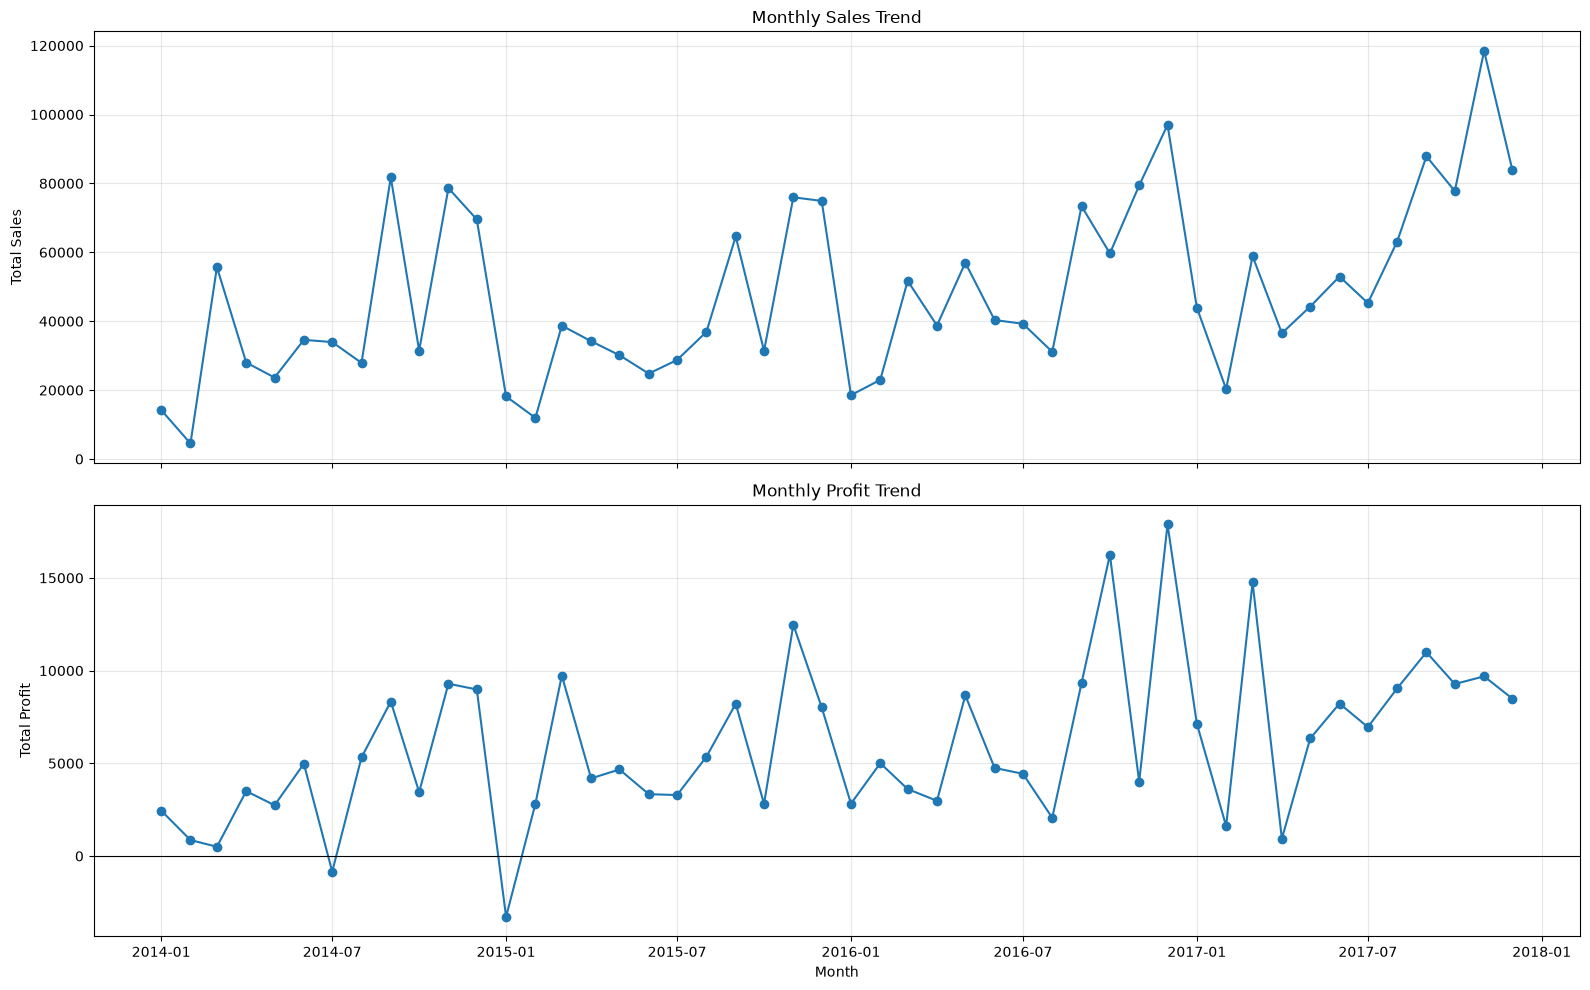

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

axes[0].plot(
    monthly_analysis["Order Date"],
    monthly_analysis["total_sales"],
    marker="o"
)
axes[0].set_title("Monthly Sales Trend")
axes[0].set_ylabel("Total Sales")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_analysis["Order Date"],
    monthly_analysis["total_profit"],
    marker="o"
)
axes[1].set_title("Monthly Profit Trend")
axes[1].set_ylabel("Total Profit")
axes[1].set_xlabel("Month")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 19. Yearly Sales and Profitability Analysis

In [22]:
yearly_analysis = (
    df.assign(year=df["Order Date"].dt.year)
    .groupby("year")
    .agg(
        unique_orders=("Order ID", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .reset_index()
)

yearly_analysis["profit_margin"] = (
    yearly_analysis["total_profit"]
    / yearly_analysis["total_sales"] * 100
)

yearly_analysis["sales_growth_pct"] = (
    yearly_analysis["total_sales"].pct_change() * 100
)

yearly_analysis["profit_growth_pct"] = (
    yearly_analysis["total_profit"].pct_change() * 100
)

display(yearly_analysis.round(2))

,year,unique_orders,unique_customers,total_quantity,total_sales,total_profit,profit_margin,sales_growth_pct,profit_growth_pct
0,2014,969,595,7579,483966.13,49556.03,10.24,NaN,NaN
1,2015,1038,573,7979,470532.51,61618.60,13.10,-2.78,24.34
2,2016,1315,638,9837,609205.60,81795.17,13.43,29.47,32.74
3,2017,1687,693,12476,733215.26,93439.27,12.74,20.36,14.24


### 20. Yearly Sales, Profit and Growth Visualization

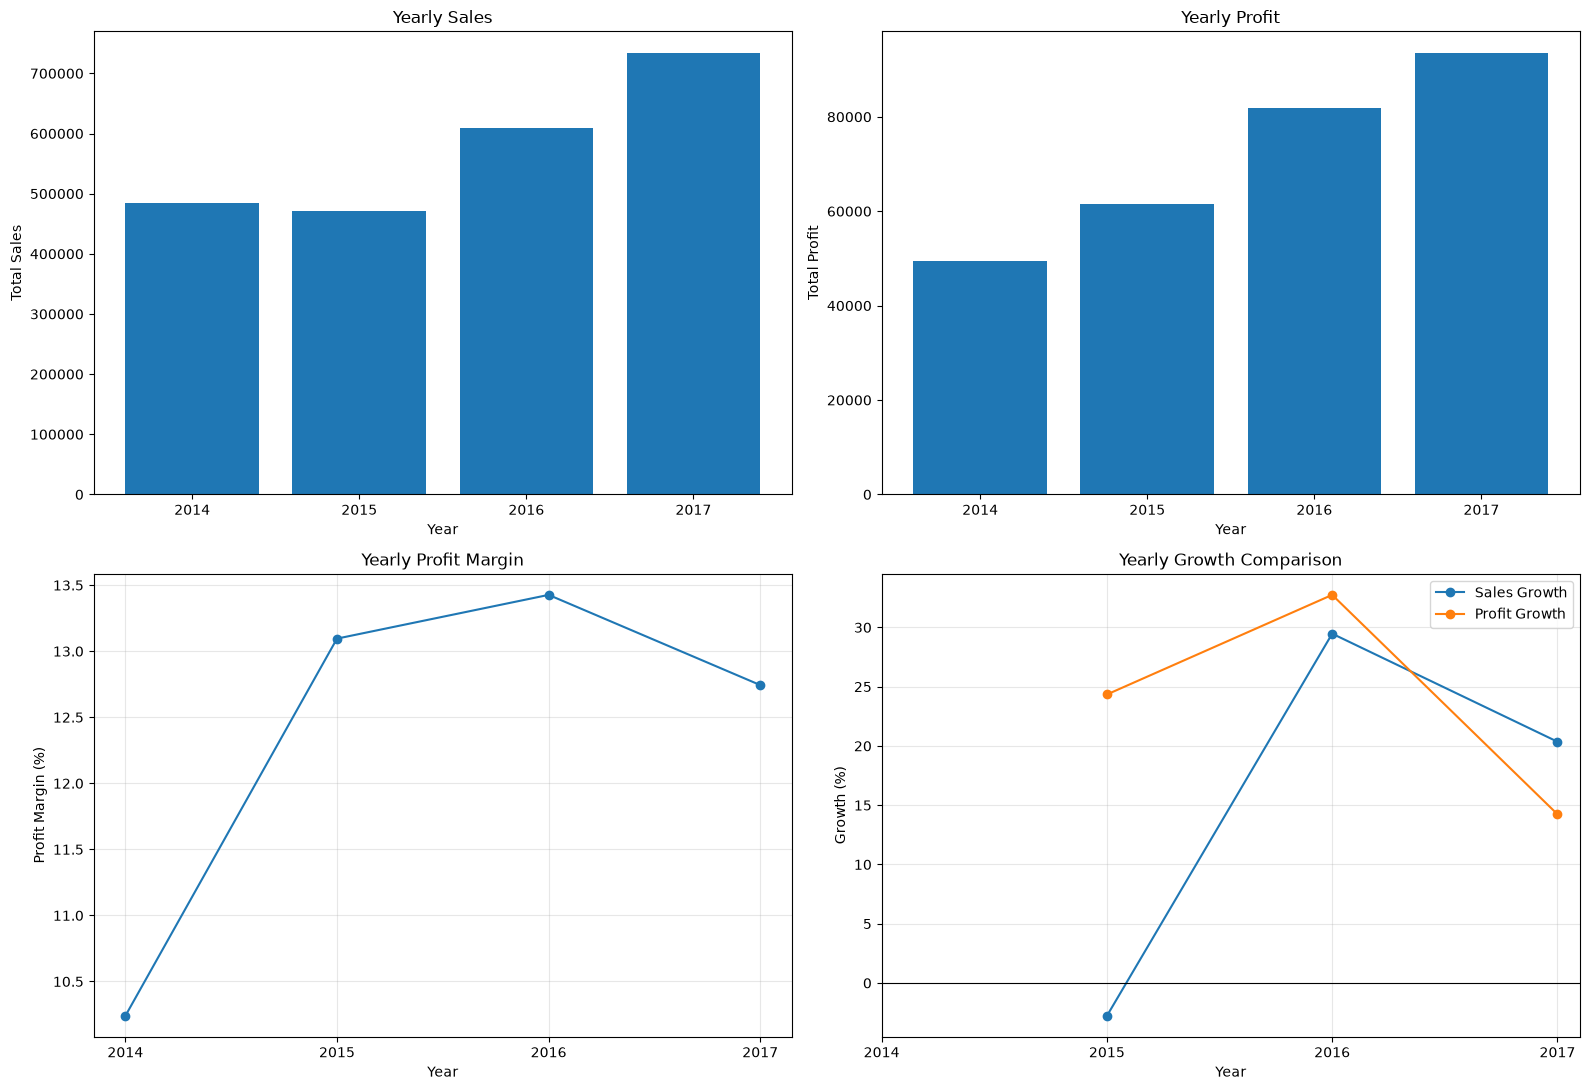

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].bar(
    yearly_analysis["year"].astype(str),
    yearly_analysis["total_sales"]
)
axes[0, 0].set_title("Yearly Sales")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Total Sales")

axes[0, 1].bar(
    yearly_analysis["year"].astype(str),
    yearly_analysis["total_profit"]
)
axes[0, 1].set_title("Yearly Profit")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Total Profit")

axes[1, 0].plot(
    yearly_analysis["year"],
    yearly_analysis["profit_margin"],
    marker="o"
)
axes[1, 0].set_title("Yearly Profit Margin")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Profit Margin (%)")
axes[1, 0].set_xticks(yearly_analysis["year"])
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(
    yearly_analysis["year"],
    yearly_analysis["sales_growth_pct"],
    marker="o",
    label="Sales Growth"
)
axes[1, 1].plot(
    yearly_analysis["year"],
    yearly_analysis["profit_growth_pct"],
    marker="o",
    label="Profit Growth"
)
axes[1, 1].set_title("Yearly Growth Comparison")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Growth (%)")
axes[1, 1].set_xticks(yearly_analysis["year"])
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Yearly Business Performance Findings

- 2015 recorded a sales decline of 2.78%, while profit increased by 24.34%.
- 2016 recorded the strongest sales growth of 29.47% and profit growth of 32.74%.
- 2017 generated the highest annual sales of $733,215.26.
- 2017 also generated the highest annual profit of $93,439.27.
- The highest annual profit margin was recorded in 2016 at 13.43%.
- Profit margin declined from 13.43% in 2016 to 12.74% in 2017.

The analysis indicates overall business growth from 2014 to 2017,
although revenue growth, profit growth and profit margin did not
follow identical patterns.

### 21. Discount-wise Sales and Profitability Analysis

In [24]:
discount_analysis = (
    df.groupby("Discount")
    .agg(
        order_lines=("Row ID", "count"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        average_profit_per_line=("Profit", "mean"),
        loss_making_lines=(
            "Profit",
            lambda profit: (profit < 0).sum()
        )
    )
    .reset_index()
)

discount_analysis["profit_margin"] = (
    discount_analysis["total_profit"]
    / discount_analysis["total_sales"] * 100
)

discount_analysis["loss_percentage"] = (
    discount_analysis["loss_making_lines"]
    / discount_analysis["order_lines"] * 100
)

display(discount_analysis.round(2))

,Discount,order_lines,total_sales,total_profit,average_profit_per_line,loss_making_lines,profit_margin,loss_percentage
0,0.00,4798,1087908.47,320987.60,66.90,0,29.51,0.00
1,0.10,94,54369.35,9029.18,96.06,4,16.61,4.26
2,0.15,52,27558.52,1418.99,27.29,17,5.15,32.69
3,0.20,3657,764594.37,90337.31,24.70,502,11.82,13.73
4,0.30,226,102945.28,-10357.22,-45.83,207,-10.06,91.59
5,0.32,27,14493.46,-2391.14,-88.56,27,-16.50,100.00
6,0.40,206,116417.78,-23057.05,-111.93,180,-19.81,87.38
7,0.45,11,5484.97,-2493.11,-226.65,11,-45.45,100.00
8,0.50,66,58918.54,-20506.43,-310.70,66,-34.80,100.00
9,0.60,138,6644.70,-5944.66,-43.08,138,-89.46,100.00


### 22. Discount-wise Profitability Visualization

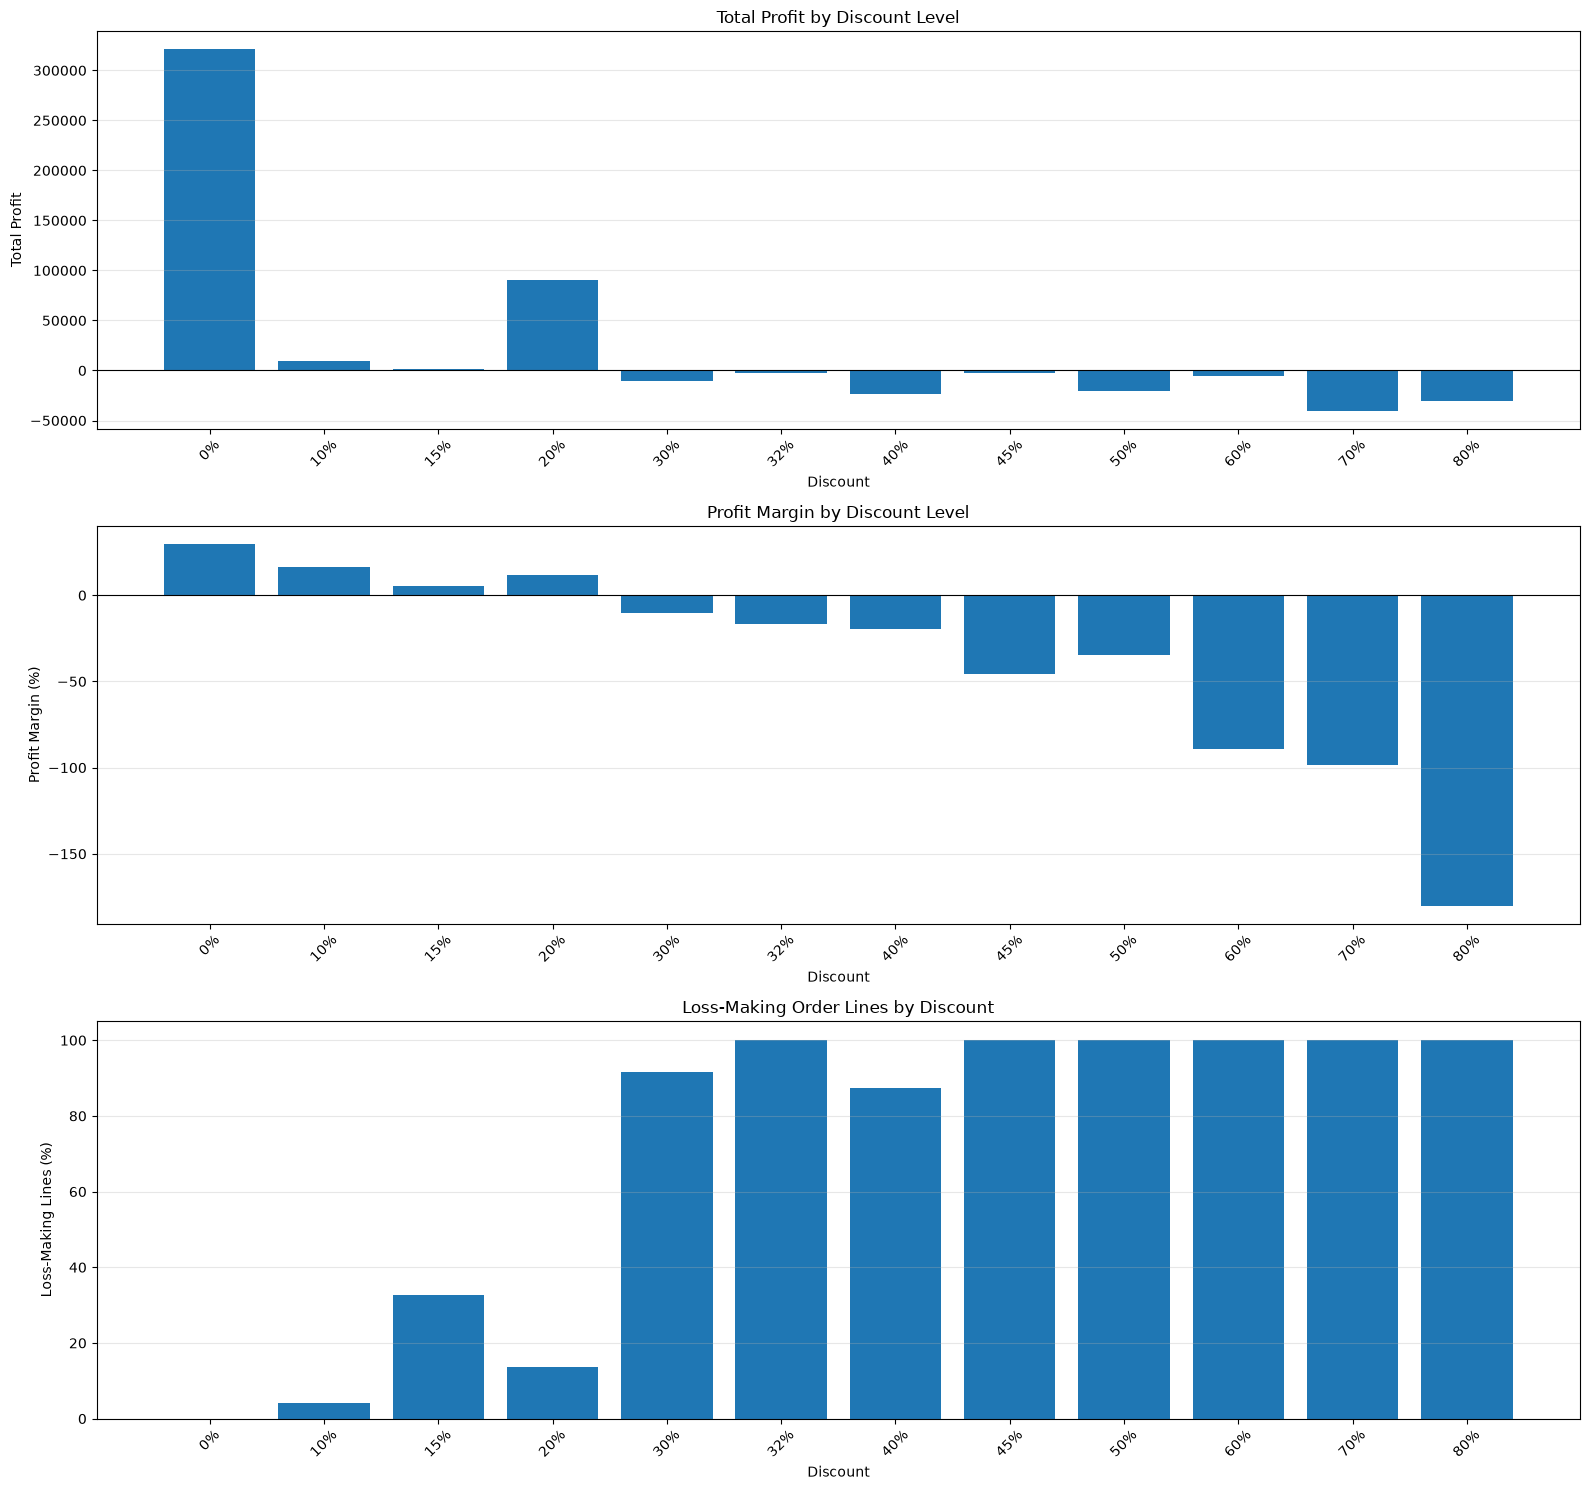

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(16, 15))

discount_labels = (
    discount_analysis["Discount"] * 100
).astype(int).astype(str) + "%"

axes[0].bar(
    discount_labels,
    discount_analysis["total_profit"]
)
axes[0].set_title("Total Profit by Discount Level")
axes[0].set_xlabel("Discount")
axes[0].set_ylabel("Total Profit")
axes[0].axhline(0, color="black", linewidth=0.8)

axes[1].bar(
    discount_labels,
    discount_analysis["profit_margin"]
)
axes[1].set_title("Profit Margin by Discount Level")
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("Profit Margin (%)")
axes[1].axhline(0, color="black", linewidth=0.8)

axes[2].bar(
    discount_labels,
    discount_analysis["loss_percentage"]
)
axes[2].set_title("Loss-Making Order Lines by Discount")
axes[2].set_xlabel("Discount")
axes[2].set_ylabel("Loss-Making Lines (%)")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Discount Effectiveness Findings

- Transactions without discounts generate the highest total profit of $320,987.60.
- The 20% discount group generates $90,337.31 in profit.
- The 15% discount group has a relatively low profit margin of 5.15%.
- The 30% discount group records a loss of $10,357.22.
- The 70% discount group records the largest loss of $40,075.36.
- All order lines with discounts of 50%, 60%, 70% and 80% are loss-making.

Higher discount levels are associated with substantially weaker profitability.
However, this analysis does not establish causation. Product mix, costs and
transaction characteristics should also be investigated.

### 23. Correlation Analysis of Numerical Variables

In [26]:
correlation_data = df[
    ["Sales", "Quantity", "Discount", "Profit"]
]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

display(correlation_matrix.round(3))

,Sales,Quantity,Discount,Profit
Sales,1.000,0.201,-0.028,0.479
Quantity,0.201,1.000,0.009,0.066
Discount,-0.028,0.009,1.000,-0.219
Profit,0.479,0.066,-0.219,1.000


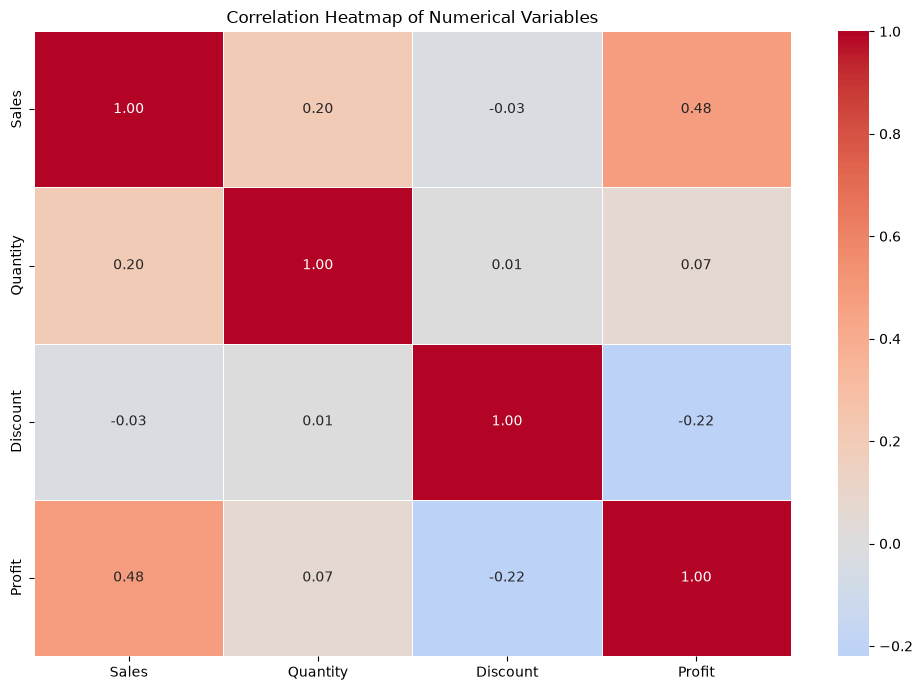

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### 24. Pearson vs Spearman Correlation Comparison

In [28]:
correlation_comparison = pd.concat(
    [
        correlation_data.corr(method="pearson").stack().rename("Pearson"),
        correlation_data.corr(method="spearman").stack().rename("Spearman")
    ],
    axis=1
)

display(correlation_comparison.round(3))

Pearson  Spearman
Sales    Sales       1.000     1.000
         Quantity    0.201     0.328
         Discount   -0.028    -0.057
         Profit      0.479     0.519
Quantity Sales       0.201     0.328
         Quantity    1.000     1.000
         Discount    0.009    -0.001
         Profit      0.066     0.234
Discount Sales      -0.028    -0.057
         Quantity    0.009    -0.001
         Discount    1.000     1.000
         Profit     -0.219    -0.543
Profit   Sales       0.479     0.519
         Quantity    0.066     0.234
         Discount   -0.219    -0.543
         Profit      1.000     1.000

### Correlation Analysis Findings

- Sales and Profit show a moderate positive relationship.
  Pearson: 0.479, Spearman: 0.519.
- Discount and Profit show a negative relationship.
  Pearson: -0.219, Spearman: -0.543.
- Quantity and Profit show a weak positive relationship.
  Pearson: 0.066, Spearman: 0.234.
- Sales and Quantity show a weak positive relationship.
- Sales and Discount show almost no linear or monotonic relationship.
- Quantity and Discount show almost no relationship.

Spearman correlation identifies a stronger negative monotonic association
between discount and profit than Pearson correlation.

Correlation does not establish causation. Product mix, costs and other
transaction characteristics may influence these relationships.

### 25. Multivariate Analysis: Category vs. Discount vs. Profitability

In [29]:
category_discount_analysis = (
    df.groupby(["Category", "Discount"])
    .agg(
        order_lines=("Row ID", "count"),
        unique_orders=("Order ID", "nunique"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        loss_making_lines=(
            "Profit",
            lambda profit: (profit < 0).sum()
        )
    )
    .reset_index()
)

category_discount_analysis["profit_margin"] = (
    category_discount_analysis["total_profit"]
    / category_discount_analysis["total_sales"] * 100
)

category_discount_analysis["loss_percentage"] = (
    category_discount_analysis["loss_making_lines"]
    / category_discount_analysis["order_lines"] * 100
)

category_discount_analysis = category_discount_analysis.sort_values(
    by=["Category", "Discount"]
)

display(category_discount_analysis.round(2))

,Category,Discount,order_lines,unique_orders,total_sales,total_profit,loss_making_lines,profit_margin,loss_percentage
0,Furniture,0.00,836,739,256025.27,58133.08,0,22.71,0.00
1,Furniture,0.10,76,71,46634.25,7111.01,4,15.25,5.26
2,Furniture,0.15,52,51,27558.52,1418.99,17,5.15,32.69
3,Furniture,0.20,615,539,216631.02,6265.95,166,2.89,26.99
4,Furniture,0.30,221,207,99188.98,-10683.26,206,-10.77,93.21
5,Furniture,0.32,27,27,14493.46,-2391.14,27,-16.50,100.00
6,Furniture,0.40,75,72,45614.41,-16187.40,75,-35.49,100.00
7,Furniture,0.45,11,10,5484.97,-2493.11,11,-45.45,100.00
8,Furniture,0.50,54,53,20983.47,-12871.20,54,-61.34,100.00
9,Furniture,0.60,138,127,6644.70,-5944.66,138,-89.46,100.00


### 26. Category vs. Discount Profitability Heatmap

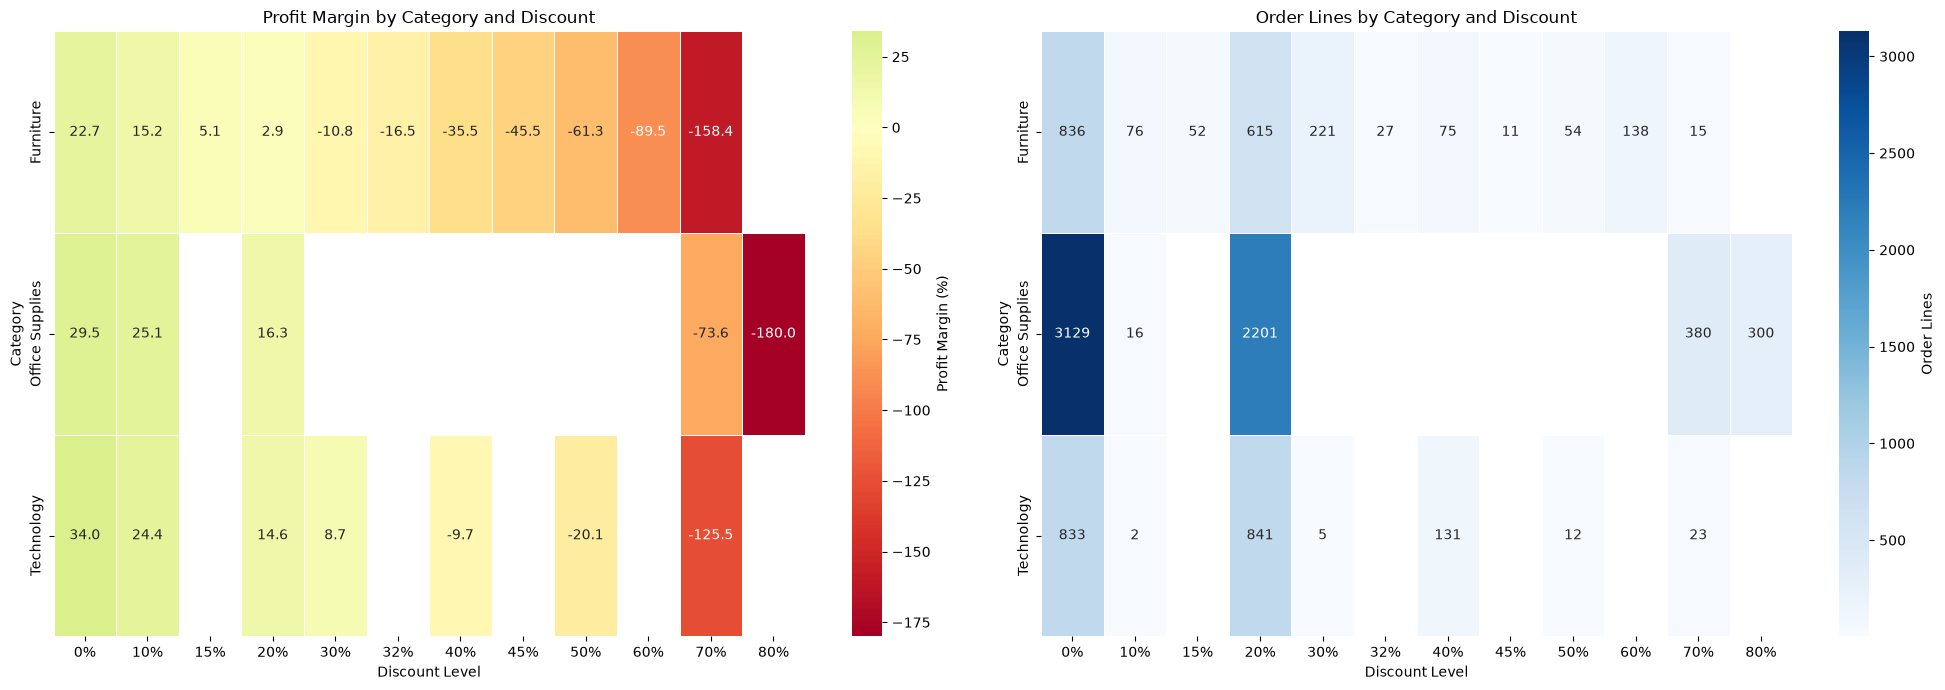

In [30]:
margin_pivot = category_discount_analysis.pivot(
    index="Category",
    columns="Discount",
    values="profit_margin"
)

count_pivot = category_discount_analysis.pivot(
    index="Category",
    columns="Discount",
    values="order_lines"
)

margin_pivot.columns = [
    f"{int(discount * 100)}%" for discount in margin_pivot.columns
]

count_pivot.columns = [
    f"{int(discount * 100)}%" for discount in count_pivot.columns
]

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

sns.heatmap(
    margin_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    mask=margin_pivot.isna(),
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Profit Margin (%)"}
)

axes[0].set_title("Profit Margin by Category and Discount")
axes[0].set_xlabel("Discount Level")
axes[0].set_ylabel("Category")

sns.heatmap(
    count_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    mask=count_pivot.isna(),
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Order Lines"}
)

axes[1].set_title("Order Lines by Category and Discount")
axes[1].set_xlabel("Discount Level")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

### Category and Discount Analysis Findings

- Furniture becomes loss-making at the observed 30% discount level.
- Technology becomes loss-making at the observed 40% discount level.
- Office Supplies records substantial losses at 70% and 80% discounts.
- Furniture records its largest observed discount-related loss at 40%.
- Office Supplies generates a loss of $30,539.04 at an 80% discount.
- Technology generates a loss of $19,579.32 at a 70% discount.

The relationship between discounts and profitability varies across
product categories.

Discount-level comparisons should consider transaction counts,
product mix and sample sizes. These associations do not establish
that discounts alone caused the observed losses.

### 27. Regional and Category-wise Profitability Analysis

In [31]:
region_category_analysis = (
    df.groupby(["Region", "Category"])
    .agg(
        order_lines=("Row ID", "count"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        total_quantity=("Quantity", "sum")
    )
    .reset_index()
)

region_category_analysis["profit_margin"] = (
    region_category_analysis["total_profit"]
    / region_category_analysis["total_sales"] * 100
)

region_category_analysis = region_category_analysis.sort_values(
    by=["Region", "total_profit"],
    ascending=[True, False]
)

display(region_category_analysis.round(2))

,Region,Category,order_lines,total_sales,total_profit,total_quantity,profit_margin
2,Central,Technology,420,170416.31,33697.43,1544,19.77
1,Central,Office Supplies,1422,167026.42,8879.98,5409,5.32
0,Central,Furniture,481,163797.16,-2871.05,1827,-1.75
5,East,Technology,535,264973.98,47462.04,1942,17.91
4,East,Office Supplies,1712,205516.06,41014.58,6462,19.96
3,East,Furniture,600,208009.83,3058.22,2212,1.47
8,South,Technology,293,148771.91,19991.83,1118,13.44
7,South,Office Supplies,995,125651.31,19986.39,3800,15.91
6,South,Furniture,332,117298.68,6771.21,1291,5.77
10,West,Office Supplies,1897,220853.25,52609.85,7235,23.82


### 28. Regional and Category-wise Profitability Heatmap

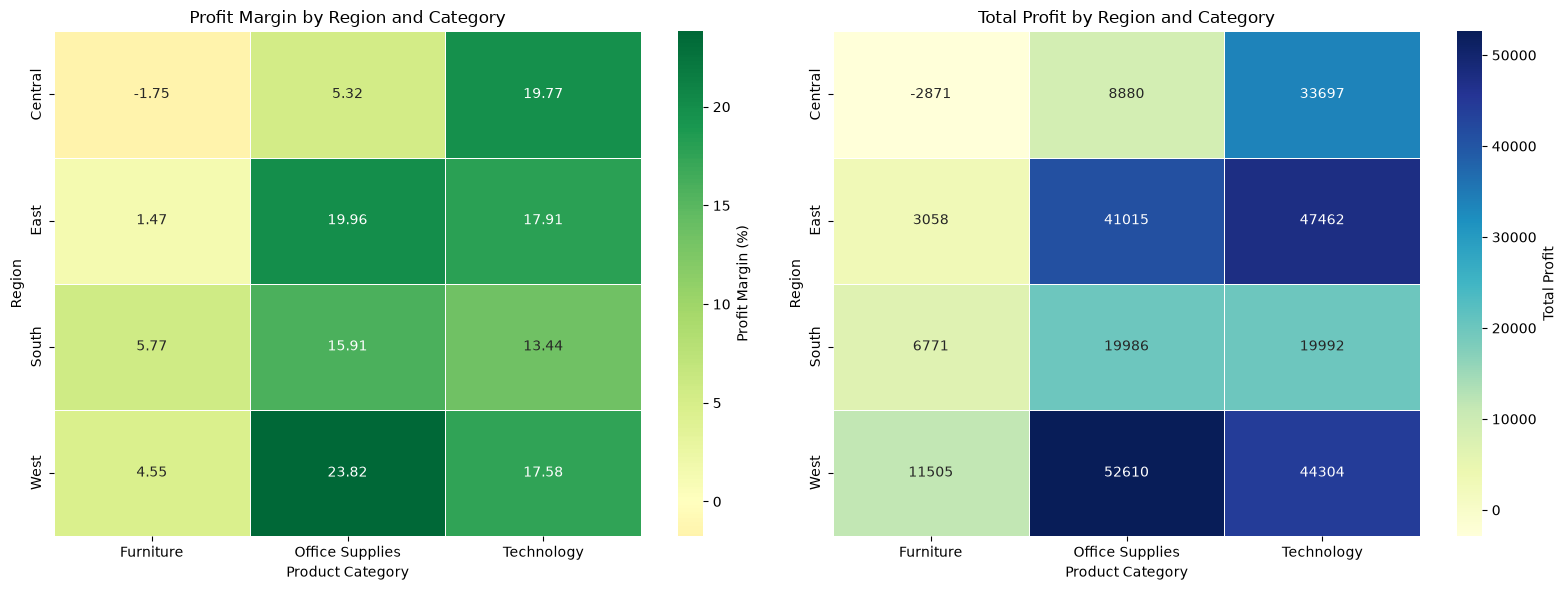

In [32]:
regional_margin_pivot = region_category_analysis.pivot(
    index="Region",
    columns="Category",
    values="profit_margin"
)

regional_profit_pivot = region_category_analysis.pivot(
    index="Region",
    columns="Category",
    values="total_profit"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    regional_margin_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Profit Margin (%)"}
)

axes[0].set_title("Profit Margin by Region and Category")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Region")

sns.heatmap(
    regional_profit_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Total Profit"}
)

axes[1].set_title("Total Profit by Region and Category")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Region")

plt.tight_layout()
plt.show()

### Regional and Category-wise Analysis Findings

- Technology generates the highest profit in Central, East and South.
- Office Supplies generates the highest profit in West.
- West Office Supplies records a profit margin of 23.82%.
- Central Furniture is the only loss-making region-category combination.
- Furniture records weak profit margins across all four regions.
- South Technology and Office Supplies generate almost identical total profits.

The results indicate that product-category performance varies across
geographical regions. Furniture in Central deserves particular attention,
while West Office Supplies represents a strong-performing combination.

### 29. Regional and Category-wise Business Insights

### Regional and Category-wise Business Insights

The regional and category-level analysis reveals differences in product profitability across geographical markets.

- Technology generates the highest profit in Central, East and South.
- Office Supplies generates the highest profit in West.
- West Office Supplies records a profit margin of 23.82% and total profit of $52,609.85.
- Central Furniture is the only loss-making region-category combination, recording a loss of $2,871.05.
- Furniture has relatively weak profit margins across all four regions.
- South Technology and Office Supplies generate almost identical total profits, differing by only $5.44.

These findings suggest that product-category performance varies by region. Central Furniture deserves further investigation, while West Office Supplies represents a strong-performing combination.

The results are descriptive and do not establish the causes of regional profitability differences.

### Title: 30. Overall Exploratory Data Analysis Findings

# Overall Exploratory Data Analysis Findings

## Dataset Overview
- Total records: 9,993
- Total columns: 21
- Unique orders: 5,009
- Unique customers: 793
- Total sales: $2,296,919.49
- Total profit: $286,409.08
- Overall profit margin: 12.47%

## Key Business Findings

### Product Performance
- Technology generates the highest category profit of $145,454.95.
- Furniture has a low profit margin of 2.49%.
- Tables, Bookcases and Supplies are loss-making subcategories.
- Copiers generates the highest subcategory profit.

### Customer Segments
- Consumer generates the highest total sales and profit.
- Home Office has the highest profit margin at 14.05%.
- Corporate has the highest sales per customer.

### Geographical Performance
- West generates the highest regional profit.
- Central has the lowest regional profit margin at 7.92%.
- Texas records the largest state-level loss.
- California generates the highest state-level profit.

### Time-Based Performance
- 2017 records the highest annual sales and profit.
- 2016 records the highest annual profit margin at 13.43%.
- November 2017 records the highest monthly sales.
- December 2016 records the highest monthly profit.

### Discount Analysis
- Transactions without discounts generate the highest total profit.
- Higher discount levels are associated with weaker profitability.
- The 70% discount group records the largest total loss.

### Correlation and Multivariate Analysis
- Sales and Profit have a moderate positive relationship.
- Discount and Profit have a negative Spearman correlation of -0.543.
- Profitability patterns differ across product categories and regions.
- Central Furniture is a loss-making region-category combination.

## Business Recommendations

1. Investigate the profitability problems in Furniture, particularly Tables.
2. Review high-discount transactions and their impact on profit.
3. Investigate loss-making states, especially Texas and Ohio.
4. Understand the factors behind Central's weak profitability.
5. Study successful categories and regional combinations to identify improvement opportunities.

## Analytical Limitations

- Outliers were investigated but retained because no clear data errors were identified.
- Correlation does not establish causation.
- Discount and regional comparisons are descriptive.
- Groups with small transaction counts should be interpreted cautiously.

## Conclusion

The analysis identifies differences in profitability across products, customers, regions, discounts and time periods.

Sales volume alone does not explain business performance. Total profit, profit margin, transaction volume and geographical performance must be considered together.